In [1]:
# Установка библиотек
!pip install pandas
!pip install numpy
!pip install matplotlib
!pip install seaborn
!pip install scikit-learn


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import LocalOutlierFactor

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

pd.set_option('display.max_columns', None)

In [3]:
df = pd.read_csv("creditcard.csv")

print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [5]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,2.238554e-15,1.724421e-15,-1.245415e-15,8.238900e-16,1.213481e-15,4.866699e-15,1.436219e-15,-3.768179e-16,9.707851e-16,1.036249e-15,6.418678e-16,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,1.088850e+00,1.020713e+00,9.992014e-01,9.952742e-01,9.585956e-01,9.153160e-01,8.762529e-01,8.493371e-01,8.381762e-01,8.140405e-01,7.709250e-01,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,-2.458826e+01,-4.797473e+00,-1.868371e+01,-5.791881e+00,-1.921433e+01,-4.498945e+00,-1.412985e+01,-2.516280e+01,-9.498746e+00,-7.213527e+00,-5.449772e+01,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,-5.354257e-01,-7.624942e-01,-4.055715e-01,-6.485393e-01,-4.255740e-01,-5.828843e-01,-4.680368e-01,-4.837483e-01,-4.988498e-01,-4.562989e-01,-2.117214e-01,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,-9.291738e-02,-3.275735e-02,1.400326e-01,-1.356806e-02,5.060132e-02,4.807155e-02,6.641332e-02,-6.567575e-02,-3.636312e-03,3.734823e-03,-6.248109e-02,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,4.539234e-01,7.395934e-01,6.182380e-01,6.625050e-01,4.931498e-01,6.488208e-01,5.232963e-01,3.996750e-01,5.008067e-01,4.589494e-01,1.330408e-01,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,2.374514e+01,1.201891e+01,7.848392e+00,7.126883e+00,1.052677e+01,8.877742e+00,1.731511e+01,9.253526e+00,5.041069e+00,5.591971e+00,3.942090e+01,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [6]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Class
0    284315
1       492
Name: count, dtype: int64


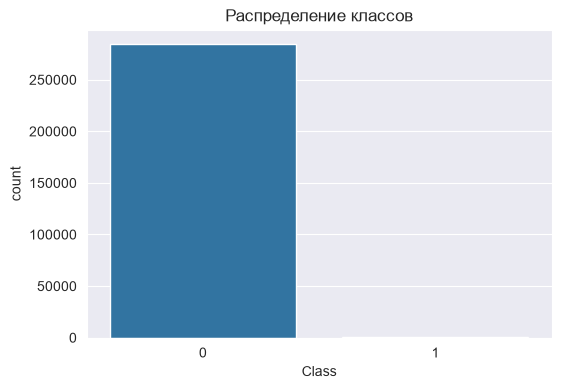

In [8]:
class_counts = df['Class'].value_counts()

print(class_counts)

plt.figure(figsize=(6,4))
sns.countplot(x='Class', data=df)
plt.title('Распределение классов')
plt.show()

In [9]:
fraud_percent = df['Class'].mean() * 100
print(f'Доля мошеннических операций: {fraud_percent:.4f}%')

Доля мошеннических операций: 0.1727%


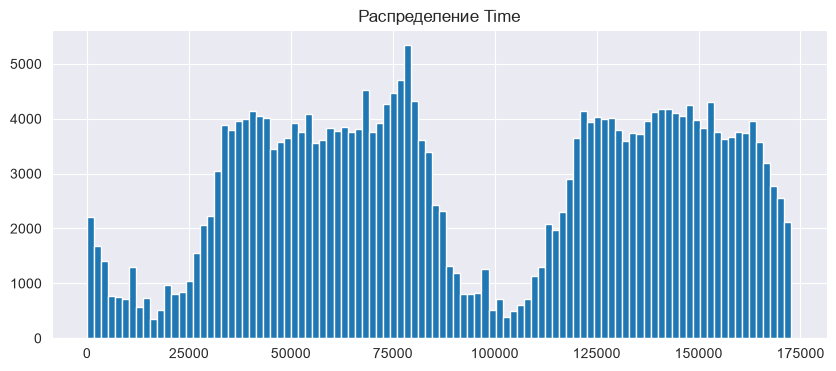

In [10]:
df['Time'].describe()
plt.figure(figsize=(10,4))
plt.hist(df['Time'], bins=100)
plt.title('Распределение Time')
plt.show()

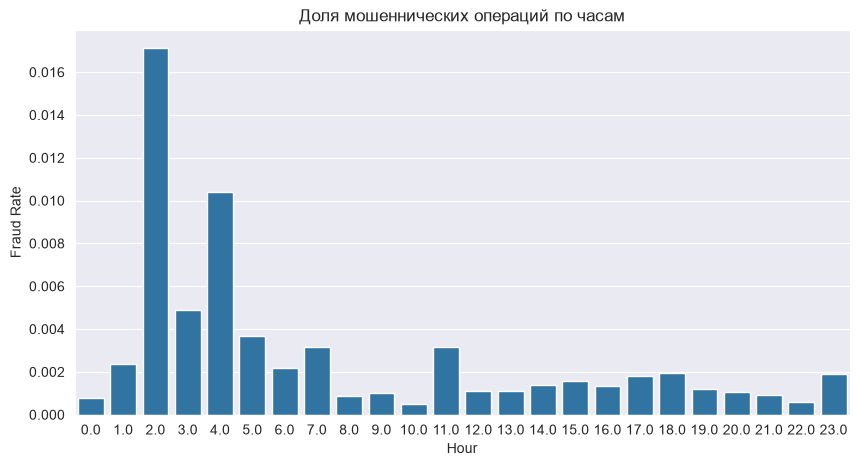

In [11]:
df['Hour'] = (df['Time'] // 3600) % 24

fraud_by_hour = (
    df.groupby('Hour')['Class']
      .mean()
      .reset_index()
)

plt.figure(figsize=(10,5))
sns.barplot(
    data=fraud_by_hour,
    x='Hour',
    y='Class'
)

plt.ylabel('Fraud Rate')
plt.title('Доля мошеннических операций по часам')
plt.show()


In [12]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Hour
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,2.238554e-15,1.724421e-15,-1.245415e-15,8.238900e-16,1.213481e-15,4.866699e-15,1.436219e-15,-3.768179e-16,9.707851e-16,1.036249e-15,6.418678e-16,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727,14.046470
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,1.088850e+00,1.020713e+00,9.992014e-01,9.952742e-01,9.585956e-01,9.153160e-01,8.762529e-01,8.493371e-01,8.381762e-01,8.140405e-01,7.709250e-01,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527,5.835854
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,-2.458826e+01,-4.797473e+00,-1.868371e+01,-5.791881e+00,-1.921433e+01,-4.498945e+00,-1.412985e+01,-2.516280e+01,-9.498746e+00,-7.213527e+00,-5.449772e+01,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,-5.354257e-01,-7.624942e-01,-4.055715e-01,-6.485393e-01,-4.255740e-01,-5.828843e-01,-4.680368e-01,-4.837483e-01,-4.988498e-01,-4.562989e-01,-2.117214e-01,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000,10.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,-9.291738e-02,-3.275735e-02,1.400326e-01,-1.356806e-02,5.060132e-02,4.807155e-02,6.641332e-02,-6.567575e-02,-3.636312e-03,3.734823e-03,-6.248109e-02,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000,15.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,4.539234e-01,7.395934e-01,6.182380e-01,6.625050e-01,4.931498e-01,6.488208e-01,5.232963e-01,3.996750e-01,5.008067e-01,4.589494e-01,1.330408e-01,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000,19.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,2.374514e+01,1.201891e+01,7.848392e+00,7.126883e+00,1.052677e+01,8.877742e+00,1.731511e+01,9.253526e+00,5.041069e+00,5.591971e+00,3.942090e+01,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000,23.000000


In [13]:
results = []

for seed in range(5):

    fraud = df[df['Class'] == 1]

    normal = df[df['Class'] == 0]

    normal_sample = normal.sample(
        n=len(fraud) * 5,
        random_state=seed
    )

    data = pd.concat([fraud, normal_sample])

    data = data.sample(
        frac=1,
        random_state=seed
    )

    X = data.drop(columns=['Class', 'Time'])
    y = data['Class']

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    lof = LocalOutlierFactor(
    n_neighbors=250,
    contamination=0.2,
    algorithm='auto',
    metric='euclidean',
    n_jobs=-1
    )

    pred = lof.fit_predict(X_scaled)

    # LOF: -1 - аномалия
    y_pred = np.where(pred == -1, 1, 0)

    scores = -lof.negative_outlier_factor_

    precision = precision_score(y, y_pred)
    recall = recall_score(y, y_pred)
    f1 = f1_score(y, y_pred)
    roc_auc = roc_auc_score(y, scores)

    results.append([
        precision,
        recall,
        f1,
        roc_auc
    ])

    print(f'Итерация {seed + 1}')
    print(f'Precision = {precision:.4f}')
    print(f'Recall    = {recall:.4f}')
    print(f'F1-score  = {f1:.4f}')
    print(f'ROC-AUC   = {roc_auc:.4f}')
    print('-' * 40)

Итерация 1
Precision = 0.5854
Recall    = 0.7033
F1-score  = 0.6390
ROC-AUC   = 0.8836
----------------------------------------
Итерация 2
Precision = 0.5753
Recall    = 0.6911
F1-score  = 0.6279
ROC-AUC   = 0.8815
----------------------------------------
Итерация 3
Precision = 0.5753
Recall    = 0.6911
F1-score  = 0.6279
ROC-AUC   = 0.8787
----------------------------------------
Итерация 4
Precision = 0.5651
Recall    = 0.6789
F1-score  = 0.6168
ROC-AUC   = 0.8748
----------------------------------------
Итерация 5
Precision = 0.5753
Recall    = 0.6911
F1-score  = 0.6279
ROC-AUC   = 0.8793
----------------------------------------



Матрица ошибок. Итерация 5
[[2209  251]
 [ 152  340]]


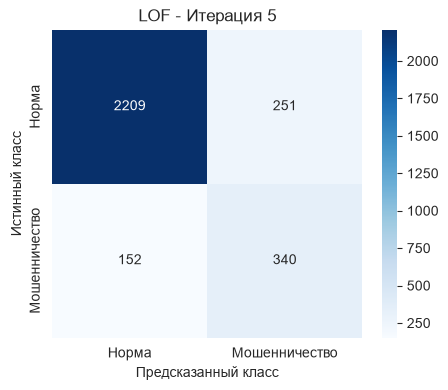

In [14]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y, y_pred)

print(f"\nМатрица ошибок. Итерация {seed+1}")
print(cm)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Норма', 'Мошенничество'],
    yticklabels=['Норма', 'Мошенничество']
)

plt.title(f'LOF - Итерация {seed+1}')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.show()

In [15]:
from sklearn.metrics import classification_report

print(classification_report(
    y,
    y_pred,
    target_names=['Normal', 'Fraud']
))

              precision    recall  f1-score   support

      Normal       0.94      0.90      0.92      2460
       Fraud       0.58      0.69      0.63       492

    accuracy                           0.86      2952
   macro avg       0.76      0.79      0.77      2952
weighted avg       0.88      0.86      0.87      2952



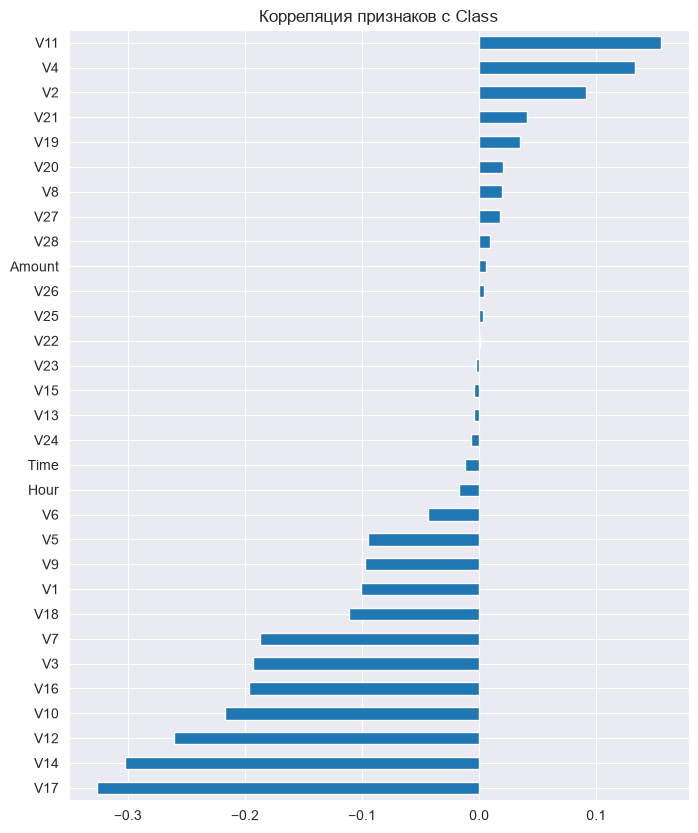

V17      -0.326481
V14      -0.302544
V12      -0.260593
V10      -0.216883
V16      -0.196539
V3       -0.192961
V7       -0.187257
V11       0.154876
V4        0.133447
V18      -0.111485
V1       -0.101347
V9       -0.097733
V5       -0.094974
V2        0.091289
V6       -0.043643
V21       0.040413
V19       0.034783
V20       0.020090
V8        0.019875
V27       0.017580
Hour     -0.017109
Time     -0.012323
V28       0.009536
V24      -0.007221
Amount    0.005632
V13      -0.004570
V26       0.004455
V15      -0.004223
V25       0.003308
V23      -0.002685
V22       0.000805
Name: Class, dtype: float64


In [16]:
corr = df.corr(numeric_only=True)

corr_class = (
    corr['Class']
    .drop('Class')
    .sort_values(key=abs, ascending=False)
)
plt.figure(figsize=(8,10))

corr_class.sort_values().plot(kind='barh')

plt.title('Корреляция признаков с Class')
plt.show()
print(corr_class)

In [17]:
#признаки по абсолютной корреляции с Class
features = [
    'V17',
    'V14',
    'V12',
    'V10',
    'V16',
    'V3',
    'V7',
    'V11',
    'V4',
    'V18'
]

results = []

for seed in range(5):

    fraud = df[df['Class'] == 1]
    normal = df[df['Class'] == 0]

    normal_sample = normal.sample(
        n=len(fraud) * 5,
        random_state=seed
    )

    data = pd.concat([fraud, normal_sample])
    data = data.sample(frac=1, random_state=seed)

    X = data[features]
    y = data['Class']

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    lof = LocalOutlierFactor(
        n_neighbors=20,
        contamination=y.mean()
    )

    pred = lof.fit_predict(X_scaled)

    y_pred = np.where(pred == -1, 1, 0)

    scores = -lof.negative_outlier_factor_

    precision = precision_score(y, y_pred)
    recall = recall_score(y, y_pred)
    f1 = f1_score(y, y_pred)
    roc_auc = roc_auc_score(y, scores)

    results.append([
        precision,
        recall,
        f1,
        roc_auc
    ])

    print(f'Итерация {seed+1}')
    print(f'Precision = {precision:.4f}')
    print(f'Recall    = {recall:.4f}')
    print(f'F1-score  = {f1:.4f}')
    print(f'ROC-AUC   = {roc_auc:.4f}')
    print('-' * 40)

    if seed == 4:
        cm = confusion_matrix(y, y_pred)

        print("\nМатрица ошибок:")
        print(cm)

        print("\nClassification Report:")
        print(
            classification_report(
                y,
                y_pred,
                target_names=['Normal', 'Fraud']
            )
        )

results = pd.DataFrame(
    results,
    columns=[
        'Precision',
        'Recall',
        'F1',
        'ROC_AUC'
    ]
)

print("\n=== СРЕДНИЕ МЕТРИКИ ===\n")
print(results.mean())

print("\n=== СТАНДАРТНОЕ ОТКЛОНЕНИЕ ===\n")
print(results.std())

Итерация 1
Precision = 0.1585
Recall    = 0.1585
F1-score  = 0.1585
ROC-AUC   = 0.4662
----------------------------------------
Итерация 2
Precision = 0.1524
Recall    = 0.1524
F1-score  = 0.1524
ROC-AUC   = 0.4829
----------------------------------------
Итерация 3
Precision = 0.1585
Recall    = 0.1585
F1-score  = 0.1585
ROC-AUC   = 0.4656
----------------------------------------
Итерация 4
Precision = 0.1606
Recall    = 0.1606
F1-score  = 0.1606
ROC-AUC   = 0.4571
----------------------------------------
Итерация 5
Precision = 0.1423
Recall    = 0.1423
F1-score  = 0.1423
ROC-AUC   = 0.4615
----------------------------------------

Матрица ошибок:
[[2038  422]
 [ 422   70]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.83      0.83      0.83      2460
       Fraud       0.14      0.14      0.14       492

    accuracy                           0.71      2952
   macro avg       0.49      0.49      0.49      2952
weighted avg       0

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix,
                             average_precision_score, classification_report,
                             precision_recall_curve, roc_curve)
import warnings
warnings.filterwarnings('ignore')



In [19]:
# временные признаки
df['Hour'] = (df['Time'] // 3600) % 24
df['Hour_sin'] = np.sin(2 * np.pi * df['Hour'] / 24)
df['Hour_cos'] = np.cos(2 * np.pi * df['Hour'] / 24)
df['Is_night'] = ((df['Hour'] >= 0) & (df['Hour'] < 6)).astype(int)

# сбалансированную выборку 1:5
fraud = df[df['Class'] == 1]
normal = df[df['Class'] == 0].sample(n=len(fraud) * 5, random_state=42)

data_balanced = pd.concat([fraud, normal]).sample(frac=1, random_state=42)

print(f"Размер сбалансированного датасета: {data_balanced.shape}")
print(f"Мошеннических: {len(fraud)}, Нормальных: {len(normal)}")
print(f"Доля мошенничества: {data_balanced['Class'].mean():.4%}")

X = data_balanced.drop(columns=['Class', 'Time'])
y = data_balanced['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Обучающая выборка: {X_train.shape}, Тестовая: {X_test.shape}")

Размер сбалансированного датасета: (2952, 35)
Мошеннических: 492, Нормальных: 2460
Доля мошенничества: 16.6667%
Обучающая выборка: (2066, 33), Тестовая: (886, 33)


In [20]:
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

rf_base = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

cv_scores_base = cross_val_score(
    rf_base,
    X_train_scaled,
    y_train,
    cv=5,
    scoring='f1'
)

print(f"F1-score на кросс-валидации:")
print(f"  Средний: {cv_scores_base.mean():.4f} ± {cv_scores_base.std():.4f}")
print(f"  Все значения: {cv_scores_base}")

rf_base.fit(X_train_scaled, y_train)
y_pred_base = rf_base.predict(X_test_scaled)
y_proba_base = rf_base.predict_proba(X_test_scaled)[:, 1]

print(f"\nРезультаты на тестовой выборке:")
print(f"F1: {f1_score(y_test, y_pred_base):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_base):.4f}")
print(f"PR-AUC: {average_precision_score(y_test, y_proba_base):.4f}")


F1-score на кросс-валидации:
  Средний: 0.9119 ± 0.0199
  Все значения: [0.87804878 0.921875   0.91338583 0.90769231 0.93846154]

Результаты на тестовой выборке:
F1: 0.9399
ROC-AUC: 0.9833
PR-AUC: 0.9586


In [21]:
# подбор параметров

# сетка параметров
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [10, 15, None],
    'min_samples_split': [2, 5],
}


X_sample, _, y_sample, _ = train_test_split(
    X_train_scaled, y_train, train_size=0.3, random_state=42, stratify=y_train
)

print(f"Размер выборки для поиска: {X_sample.shape}")


cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

rf = RandomForestClassifier(random_state=42, n_jobs=-1)
grid_search = GridSearchCV(
    rf,
    param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    verbose=0
)
grid_search.fit(X_sample, y_sample)

print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"Лучший F1 (CV): {grid_search.best_score_:.4f}")


Размер выборки для поиска: (619, 33)
Лучшие параметры: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
Лучший F1 (CV): 0.9039


In [22]:
# кросс-валидация
best_rf = grid_search.best_estimator_

cv_scores_best = cross_val_score(
    best_rf,
    X_train_scaled,
    y_train,
    cv=5,
    scoring='f1'
)

print(f"F1-score на кросс-валидации:")
print(f"  Средний: {cv_scores_best.mean():.4f} ± {cv_scores_best.std():.4f}")
print(f"  Все значения: {cv_scores_best}")

# на всех данных
best_rf.fit(X_train_scaled, y_train)
y_pred_best = best_rf.predict(X_test_scaled)
y_proba_best = best_rf.predict_proba(X_test_scaled)[:, 1]

F1-score на кросс-валидации:
  Средний: 0.9071 ± 0.0213
  Все значения: [0.87804878 0.921875   0.9047619  0.89230769 0.93846154]


In [23]:
#на тесте
precision_best = precision_score(y_test, y_pred_best)
recall_best = recall_score(y_test, y_pred_best)
f1_best = f1_score(y_test, y_pred_best)
roc_auc_best = roc_auc_score(y_test, y_proba_best)
pr_auc_best = average_precision_score(y_test, y_proba_best)

print(f"Precision: {precision_best:.4f}")
print(f"Recall:    {recall_best:.4f}")
print(f"F1:        {f1_best:.4f}")
print(f"ROC-AUC:   {roc_auc_best:.4f}")
print(f"PR-AUC:    {pr_auc_best:.4f}")

# Матрица ошибок
cm = confusion_matrix(y_test, y_pred_best)
print(f"\nМатрица ошибок:\n{cm}")

print(f"\nClassification Report:")
print(classification_report(y_test, y_pred_best, target_names=['Normal', 'Fraud']))

Precision: 0.9852
Recall:    0.8986
F1:        0.9399
ROC-AUC:   0.9816
PR-AUC:    0.9565

Матрица ошибок:
[[736   2]
 [ 15 133]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.98      1.00      0.99       738
       Fraud       0.99      0.90      0.94       148

    accuracy                           0.98       886
   macro avg       0.98      0.95      0.96       886
weighted avg       0.98      0.98      0.98       886



In [24]:
# сравнение
comparison_df = pd.DataFrame({
    'Метрика': ['F1 (CV)', 'F1 (Test)', 'ROC-AUC', 'PR-AUC'],
    'Базовая': [
        cv_scores_base.mean(),
        f1_score(y_test, y_pred_base),
        roc_auc_score(y_test, y_proba_base),
        average_precision_score(y_test, y_proba_base)
    ],
    'Оптимизированная': [
        cv_scores_best.mean(),
        f1_best,
        roc_auc_best,
        pr_auc_best
    ]
})
print(comparison_df.to_string(index=False))

  Метрика  Базовая  Оптимизированная
  F1 (CV) 0.911893          0.907091
F1 (Test) 0.939929          0.939929
  ROC-AUC 0.983337          0.981561
   PR-AUC 0.958584          0.956454


In [25]:
# важность признаков
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': best_rf.feature_importances_
}).sort_values('importance', ascending=False)

print("\nТоп-10 важных признаков:")
print(feature_importance.head(10).to_string(index=False))


Топ-10 важных признаков:
feature  importance
    V14    0.201741
    V10    0.158583
    V17    0.086974
    V12    0.086078
     V4    0.072783
     V3    0.063299
    V11    0.062414
    V16    0.058524
     V7    0.034508
     V9    0.017693


In [26]:
#порог
thresholds = np.linspace(0.1, 0.9, 50)
best_threshold = 0.5
best_f1 = 0

for threshold in thresholds:
    y_pred_threshold = (y_proba_best >= threshold).astype(int)
    f1 = f1_score(y_test, y_pred_threshold)
    if f1 > best_f1:
        best_f1 = f1
        best_threshold = threshold

print(f"\nОптимальный порог: {best_threshold:.3f}")
print(f"F1 при оптимальном пороге: {best_f1:.4f}")



Оптимальный порог: 0.524
F1 при оптимальном пороге: 0.9433


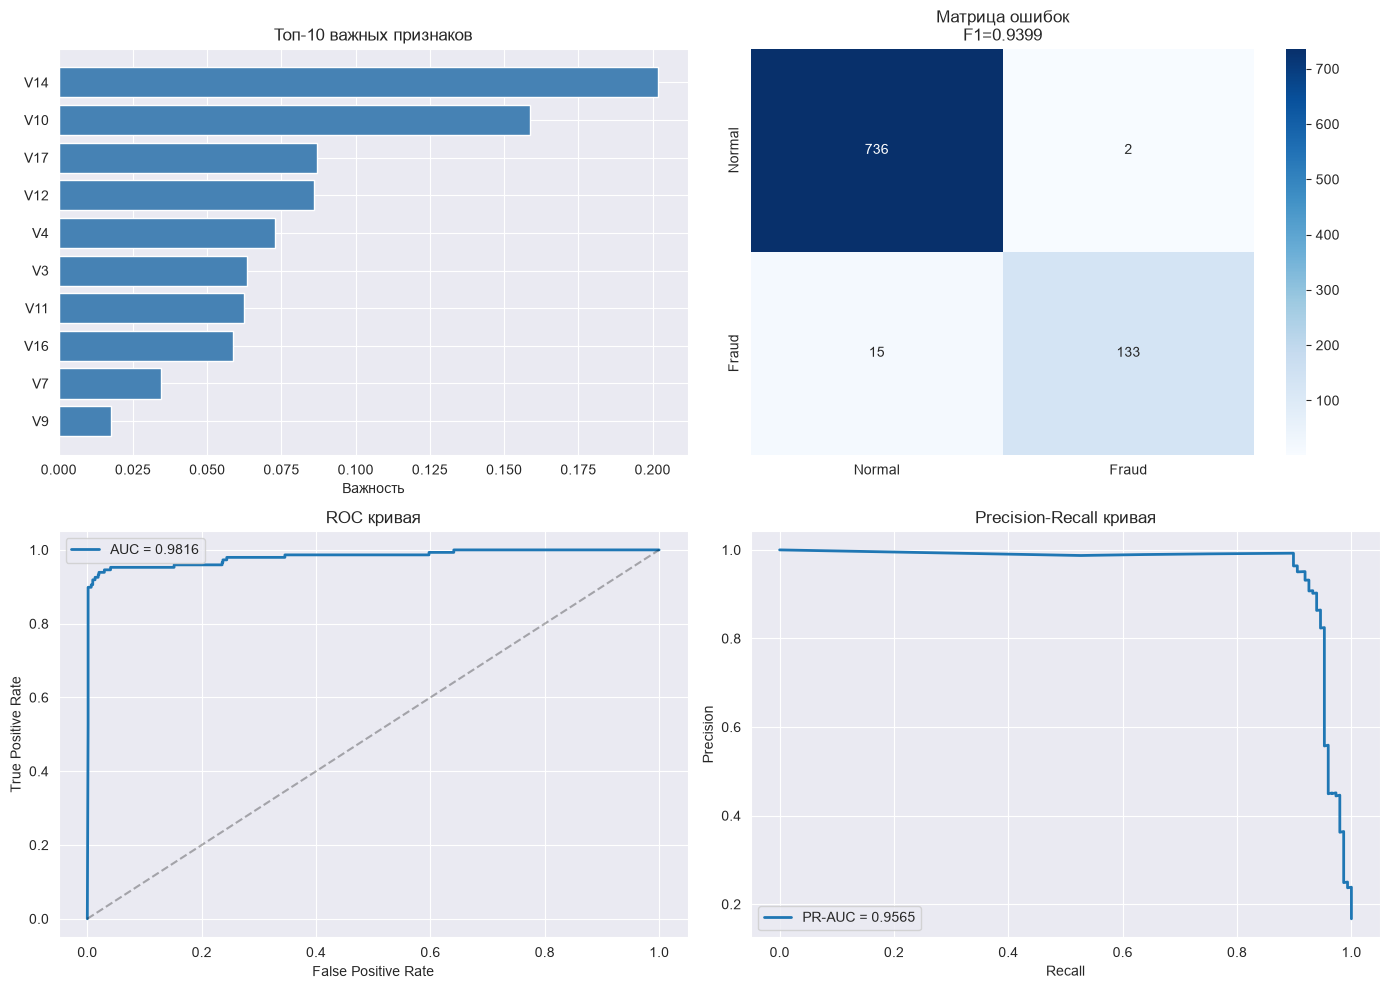


1. Балансировка: 1:5 (fraud:normal)
2. Лучшие параметры: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
3. Кросс-валидация (5-fold):
   - Базовая: 0.9119 ± 0.0199
   - Оптимизированная: 0.9071 ± 0.0213
4. Тестовая выборка:
   - F1-score: 0.9399
   - ROC-AUC: 0.9816
   - PR-AUC: 0.9565
5. Оптимальный порог: 0.524
6. Важнейшие признаки: ['V14', 'V10', 'V17']



In [27]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Важность признаков
ax = axes[0, 0]
top_features = feature_importance.head(10)
ax.barh(top_features['feature'], top_features['importance'], color='steelblue')
ax.set_xlabel('Важность')
ax.set_title('Топ-10 важных признаков')
ax.invert_yaxis()

# 2. Матрица ошибок
ax = axes[0, 1]
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Normal', 'Fraud'],
            yticklabels=['Normal', 'Fraud'])
ax.set_title(f'Матрица ошибок\nF1={f1_best:.4f}')

# 3. ROC кривая
ax = axes[1, 0]
fpr, tpr, _ = roc_curve(y_test, y_proba_best)
ax.plot(fpr, tpr, label=f'AUC = {roc_auc_best:.4f}', linewidth=2)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC кривая')
ax.legend()

# 4. Precision-Recall кривая
ax = axes[1, 1]
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_proba_best)
ax.plot(recall_curve, precision_curve, label=f'PR-AUC = {pr_auc_best:.4f}', linewidth=2)
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall кривая')
ax.legend()

plt.tight_layout()
plt.show()


print(f"""
1. Балансировка: 1:5 (fraud:normal)
2. Лучшие параметры: {grid_search.best_params_}
3. Кросс-валидация (5-fold):
   - Базовая: {cv_scores_base.mean():.4f} ± {cv_scores_base.std():.4f}
   - Оптимизированная: {cv_scores_best.mean():.4f} ± {cv_scores_best.std():.4f}
4. Тестовая выборка:
   - F1-score: {f1_best:.4f}
   - ROC-AUC: {roc_auc_best:.4f}
   - PR-AUC: {pr_auc_best:.4f}
5. Оптимальный порог: {best_threshold:.3f}
6. Важнейшие признаки: {feature_importance.head(3)['feature'].tolist()}
""")